In [258]:
import pandas as pd
import numpy as np
from functools import reduce
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

In [259]:
df1 = pd.read_csv('market_data.csv')
print(df1.shape)
df1.head()
df1['month'] = pd.to_datetime(df1['month'])
df1.tail()

(256, 8)


,month,us_crude_inventory,cushing_inventory,refinery_utilization,us_crude_imports,us_crude_exports,global_oil_consumption,opec_crude_production
251,2027-08-01,NaN,NaN,NaN,NaN,NaN,105.657801,24.925
252,2027-09-01,NaN,NaN,NaN,NaN,NaN,105.838743,24.940
253,2027-10-01,NaN,NaN,NaN,NaN,NaN,104.678448,24.955
254,2027-11-01,NaN,NaN,NaN,NaN,NaN,105.457513,24.990
255,2027-12-01,NaN,NaN,NaN,NaN,NaN,106.635925,25.005


In [260]:
df2 = pd.read_csv('state_production.csv')


df2 = df2.rename(columns={'total_production': 'total_US_production', 'old_col2': 'new_col2'})

print(df2.shape)
df2.tail()
df2['month'] = pd.to_datetime(df2['month'])
df2.info()

(238, 8)
<class 'pandas.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   month                238 non-null    datetime64[us]
 1   Alaska               238 non-null    int64         
 2   California           238 non-null    int64         
 3   Colorado             238 non-null    int64         
 4   New Mexico           238 non-null    int64         
 5   North Dakota         238 non-null    int64         
 6   Texas                238 non-null    int64         
 7   total_US_production  238 non-null    int64         
dtypes: datetime64[us](1), int64(7)
memory usage: 15.0 KB


In [261]:
df3 = pd.read_csv('oil_prices.csv')
print(df3.shape)
df3['month'] = pd.to_datetime(df3['month'])
df3.info()

(238, 3)
<class 'pandas.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   month        238 non-null    datetime64[us]
 1   brent_price  238 non-null    float64       
 2   wti_price    238 non-null    float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 5.7 KB


In [262]:
df4 = pd.read_csv("usd_index.csv")
df4.head(20)
df4['month'] = pd.to_datetime(df4['month'])
df4.info()

<class 'pandas.DataFrame'>
RangeIndex: 248 entries, 0 to 247
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   month      248 non-null    datetime64[us]
 1   usd_index  248 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 4.0 KB


In [263]:
df5 = pd.read_csv("non_opec_production.csv")
df5 = df5[['month', 'total_non_opec_production_mbpd']]
df5['month'] = pd.to_datetime(df5['month'])
df5.head()

,month,total_non_opec_production_mbpd
0,2006-09-01,44.297514
1,2006-10-01,44.736178
2,2006-11-01,44.872222
3,2006-12-01,44.786917
4,2007-01-01,45.125933


In [264]:
dfs = [df1,df2,df3,df4,df5]

df = reduce(lambda left,right: pd.merge(left,right, on = 'month', how = 'left'),dfs)
df = df[df['month'] < '2026-06']
df['month'] = df['month'].dt.to_period('M')
df = df.drop(columns = ['Alaska', 'California' ,'Colorado', 'New Mexico' ,'North Dakota', 'Texas'])

In [265]:
df.tail()

,month,us_crude_inventory,cushing_inventory,refinery_utilization,us_crude_imports,us_crude_exports,global_oil_consumption,opec_crude_production,total_US_production,brent_price,wti_price,usd_index,total_non_opec_production_mbpd
232,2026-01,318898.0,24498.0,91.4,6469.0,3922.0,102.275734,25.125,9924.0,66.602381,60.037000,119.2298,53.908741
233,2026-02,343514.0,25188.0,89.0,6457.0,4345.0,104.240760,25.950,10355.0,70.887000,64.508421,117.9060,55.174074
234,2026-03,363357.0,32110.0,91.6,6536.0,4043.0,102.009110,18.430,10345.0,103.134545,91.383636,119.9199,54.399978
235,2026-04,362928.0,28272.0,90.1,6257.0,5593.0,99.439357,16.850,10469.0,117.287500,100.316667,119.0363,54.654532
236,2026-05,337227.0,20462.0,94.0,5953.0,5728.0,99.848860,16.380,10438.0,107.139474,102.134000,118.7792,53.648552


In [266]:
df.to_csv("master_table.csv", index = False)

In [267]:
df.describe()

,us_crude_inventory,cushing_inventory,refinery_utilization,us_crude_imports,us_crude_exports,global_oil_consumption,opec_crude_production,total_US_production,brent_price,wti_price,usd_index,total_non_opec_production_mbpd
count,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000
mean,301294.185654,37192.037975,88.592827,7686.481013,1612.248945,95.076727,24.917798,6380.810127,77.496440,72.634420,106.567034,49.009579
std,67895.908240,14292.409837,4.687017,1332.664931,1673.335933,5.935968,1.760593,2719.324307,23.998714,21.454440,12.454477,3.208260
min,174050.000000,11691.000000,70.200000,5293.000000,9.000000,83.686986,16.380000,2649.000000,18.378500,16.547619,86.317800,43.109376
25%,240455.000000,25505.000000,86.200000,6474.000000,60.000000,90.069743,24.250000,3307.000000,61.477727,57.027000,93.670000,45.775556
50%,324255.000000,34809.000000,89.000000,7570.000000,599.000000,95.524285,24.967900,6265.000000,74.456364,71.578182,110.889200,49.304810
75%,349420.000000,47273.000000,91.900000,8711.000000,3343.000000,100.306216,26.215000,8869.000000,97.129000,89.145909,116.945300,51.752577
max,432034.000000,69414.000000,97.000000,10710.000000,5728.000000,105.910921,27.611300,10498.000000,132.718182,133.880000,128.836900,55.430977


In [217]:
df.isnull().sum()

month                             0
us_crude_inventory                0
cushing_inventory                 0
refinery_utilization              0
us_crude_imports                  0
us_crude_exports                  0
global_oil_consumption            0
opec_crude_production             0
total_US_production               0
brent_price                       0
wti_price                         0
usd_index                         0
total_non_opec_production_mbpd    0
dtype: int64

In [218]:
correlation_matrix = df.corr(numeric_only = True)
correlation_matrix

,us_crude_inventory,cushing_inventory,refinery_utilization,us_crude_imports,us_crude_exports,global_oil_consumption,opec_crude_production,total_US_production,brent_price,wti_price,usd_index,total_non_opec_production_mbpd
us_crude_inventory,1.000000,0.595452,0.083043,-0.762387,0.665239,0.690816,-0.285489,0.767982,-0.533877,-0.583435,0.844923,0.705963
cushing_inventory,0.595452,1.000000,-0.114300,-0.196361,-0.110139,0.111536,0.100057,0.055822,-0.472664,-0.564925,0.171389,0.048939
refinery_utilization,0.083043,-0.114300,1.000000,-0.046499,0.185542,0.561016,0.309700,0.315927,0.134662,0.120102,0.236839,0.405539
us_crude_imports,-0.762387,-0.196361,-0.046499,1.000000,-0.812729,-0.726751,0.519061,-0.898381,0.172261,0.223913,-0.777704,-0.821603
us_crude_exports,0.665239,-0.110139,0.185542,-0.812729,1.000000,0.768154,-0.535874,0.935994,-0.141059,-0.155844,0.875960,0.866232
global_oil_consumption,0.690816,0.111536,0.561016,-0.726751,0.768154,1.000000,-0.089490,0.888249,-0.135560,-0.178439,0.808405,0.904590
opec_crude_production,-0.285489,0.100057,0.309700,0.519061,-0.535874,-0.089490,1.000000,-0.394937,-0.018070,-0.010030,-0.311206,-0.257901
total_US_production,0.767982,0.055822,0.315927,-0.898381,0.935994,0.888249,-0.394937,1.000000,-0.195668,-0.233184,0.910075,0.959287
brent_price,-0.533877,-0.472664,0.134662,0.172261,-0.141059,-0.135560,-0.018070,-0.195668,1.000000,0.973778,-0.469854,-0.206357
wti_price,-0.583435,-0.564925,0.120102,0.223913,-0.155844,-0.178439,-0.010030,-0.233184,0.973778,1.000000,-0.480861,-0.246606


### Data quality checks

In [219]:
df.shape

(237, 13)

In [220]:
df.isnull().sum()


month                             0
us_crude_inventory                0
cushing_inventory                 0
refinery_utilization              0
us_crude_imports                  0
us_crude_exports                  0
global_oil_consumption            0
opec_crude_production             0
total_US_production               0
brent_price                       0
wti_price                         0
usd_index                         0
total_non_opec_production_mbpd    0
dtype: int64

In [221]:
df.duplicated().sum()

np.int64(0)

In [222]:
#Outlier_detection


numeric_cols = df.select_dtypes(include=['number']).columns                            # Selecting numeric columns

outlier_counts = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    

    col_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()           # Counting outliers
    outlier_counts[col] = col_outliers

print(outlier_counts)


{'us_crude_inventory': np.int64(0), 'cushing_inventory': np.int64(0), 'refinery_utilization': np.int64(7), 'us_crude_imports': np.int64(0), 'us_crude_exports': np.int64(0), 'global_oil_consumption': np.int64(0), 'opec_crude_production': np.int64(12), 'total_US_production': np.int64(0), 'brent_price': np.int64(0), 'wti_price': np.int64(0), 'usd_index': np.int64(0), 'total_non_opec_production_mbpd': np.int64(0)}


In [223]:

series = df['refinery_utilization']


q1 = series.quantile(0.25)
q3 = series.quantile(0.75)


iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr


df[(series < lower_bound) | (series > upper_bound)][["month", "refinery_utilization"]]
                                 



,month,refinery_utilization
24,2008-09,74.6
163,2020-04,70.2
164,2020-05,72.0
165,2020-06,76.4
168,2020-09,76.9
169,2020-10,75.3
173,2021-02,70.6


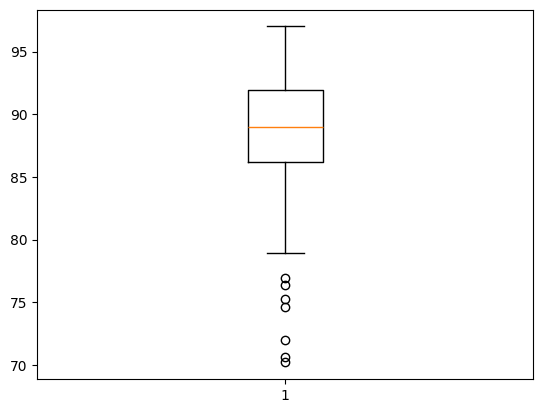

In [224]:
#outlier detection
plt.boxplot(df['refinery_utilization'].dropna())
plt.show()

### Univariate and Bivariate Analysis

#### Univariate

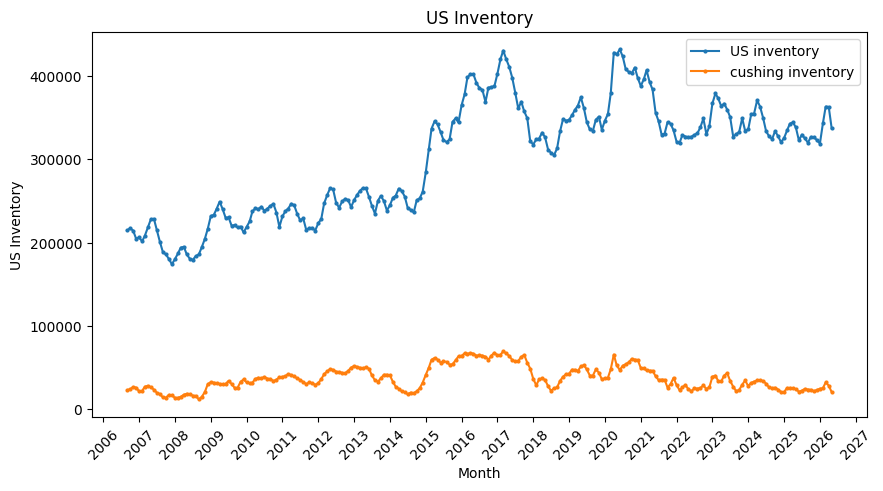

In [225]:
plt.figure(figsize = (10,5))
plt.plot(df['month'].dt.to_timestamp(), df['us_crude_inventory'], marker = 'o',markersize = 2 ,label = 'US inventory')
plt.plot(df['month'].dt.to_timestamp(), df['cushing_inventory'], marker = 'o',markersize = 2 ,label = 'cushing inventory')
plt.xlabel('Month')
plt.ylabel('US Inventory')
plt.title('US Inventory')

plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.xticks(rotation=45)

plt.legend()
plt.show()

during housing crisis and COVID the inventory hit all time low 


cushing inventory hit lowest at 2014, also in 2016 and peaked in 2016, dont show any realtion

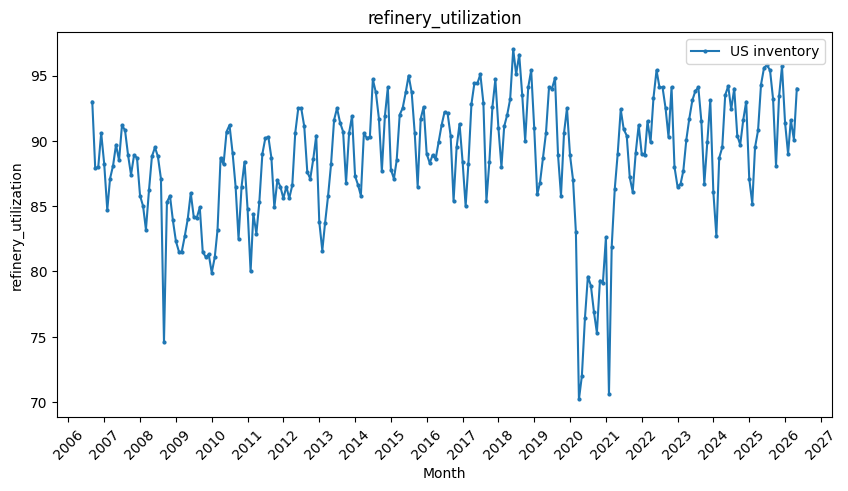

In [226]:
plt.figure(figsize = (10,5))
plt.plot(df['month'].dt.to_timestamp(), df['refinery_utilization'], marker = 'o',markersize = 2 ,label = 'US inventory')
plt.xlabel('Month')
plt.ylabel('refinery_utilization')
plt.title('refinery_utilization')

plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.xticks(rotation=45)

plt.legend()
plt.show()

this is reasonable, to covid and housing crisis

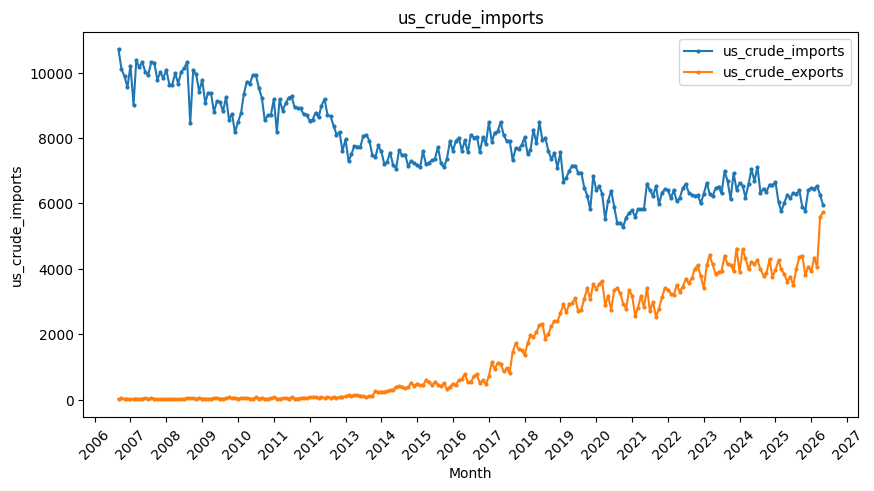

In [227]:
plt.figure(figsize = (10,5))
plt.plot(df['month'].dt.to_timestamp(), df['us_crude_imports'], marker = 'o',markersize = 2 ,label = 'us_crude_imports')
plt.plot(df['month'].dt.to_timestamp(), df['us_crude_exports'], marker = 'o',markersize = 2 ,label = 'us_crude_exports')

plt.xlabel('Month')
plt.xlabel('Month')
plt.ylabel('us_crude_imports')
plt.title('us_crude_imports')

plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.xticks(rotation=45)

plt.legend()
plt.show()

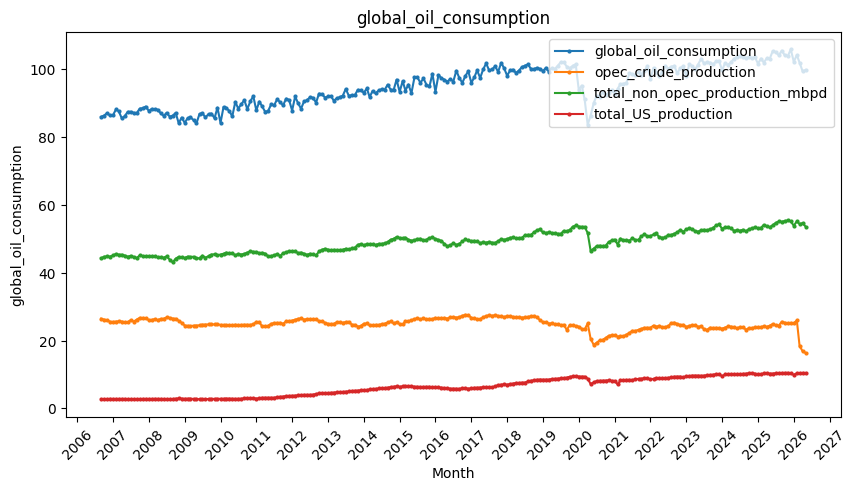

In [228]:
plt.figure(figsize = (10,5))
plt.plot(df['month'].dt.to_timestamp(), df['global_oil_consumption'], marker = 'o',markersize = 2 ,label = 'global_oil_consumption')
plt.plot(df['month'].dt.to_timestamp(), df['opec_crude_production'], marker = 'o',markersize = 2 ,label = 'opec_crude_production')
plt.plot(df['month'].dt.to_timestamp(), df['total_non_opec_production_mbpd'], marker = 'o',markersize = 2 ,label = 'total_non_opec_production_mbpd')
plt.plot(df['month'].dt.to_timestamp(), df['total_US_production']/1000, marker = 'o',markersize = 2 ,label = 'total_US_production')
plt.xlabel('Month')
plt.ylabel('global_oil_consumption')
plt.title('global_oil_consumption')

plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.xticks(rotation=45)

plt.legend()
plt.show()


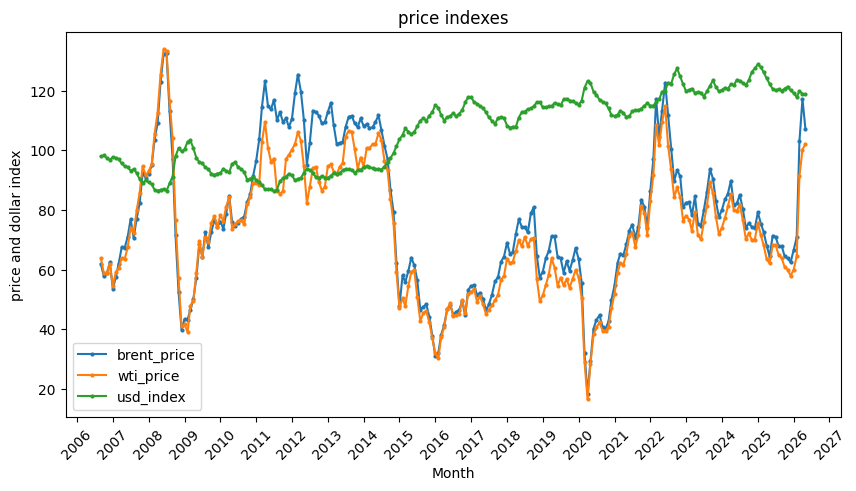

In [229]:
plt.figure(figsize = (10,5))
plt.plot(df['month'].dt.to_timestamp(), df['brent_price'], marker = 'o',markersize = 2 ,label = 'brent_price')
plt.plot(df['month'].dt.to_timestamp(), df['wti_price'], marker = 'o',markersize = 2 ,label = 'wti_price')
plt.plot(df['month'].dt.to_timestamp(), df['usd_index'], marker = 'o',markersize = 2 ,label = 'usd_index')
plt.xlabel('Month')
plt.ylabel('price and dollar index')
plt.title('price indexes')

plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.xticks(rotation=45)

plt.legend()
plt.show()

In [234]:
drivers = [
    'wti_price',
    'opec_crude_production',
    'total_non_opec_production_mbpd',
    'global_oil_consumption',
    'total_US_production',
    'us_crude_imports',
    'us_crude_exports',
    'usd_index',
    'us_crude_inventory'
]

In [235]:
for col in drivers:
    corr = df['brent_price'].corr(df[col])

    print(f"Brent vs {col}: {corr:.3f}")

Brent vs wti_price: 0.974
Brent vs opec_crude_production: -0.018
Brent vs total_non_opec_production_mbpd: -0.206
Brent vs global_oil_consumption: -0.136
Brent vs total_US_production: -0.196
Brent vs us_crude_imports: 0.172
Brent vs us_crude_exports: -0.141
Brent vs usd_index: -0.470
Brent vs us_crude_inventory: -0.534


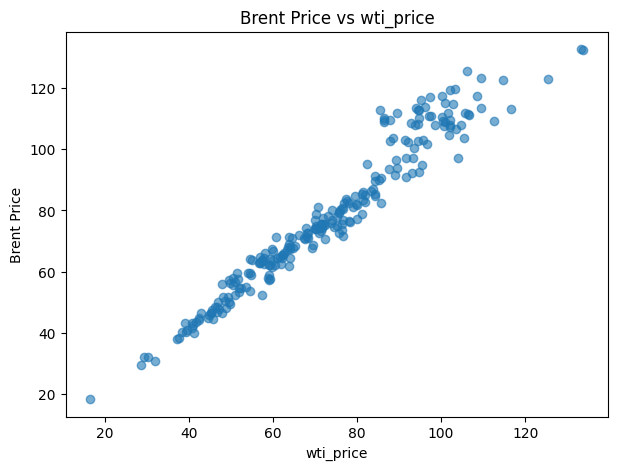

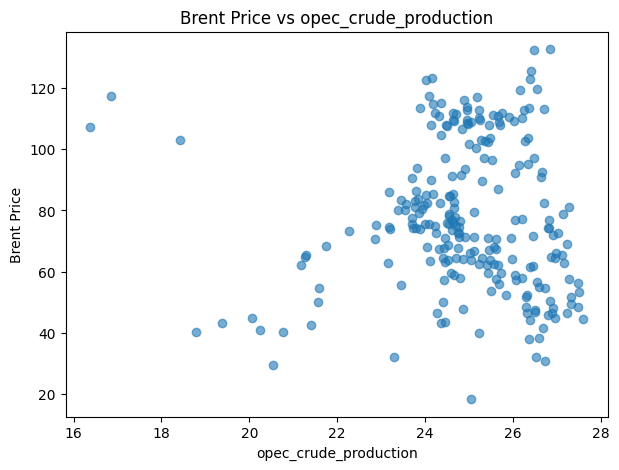

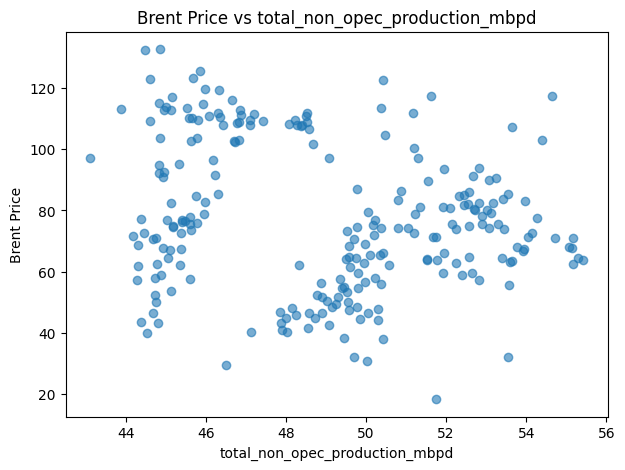

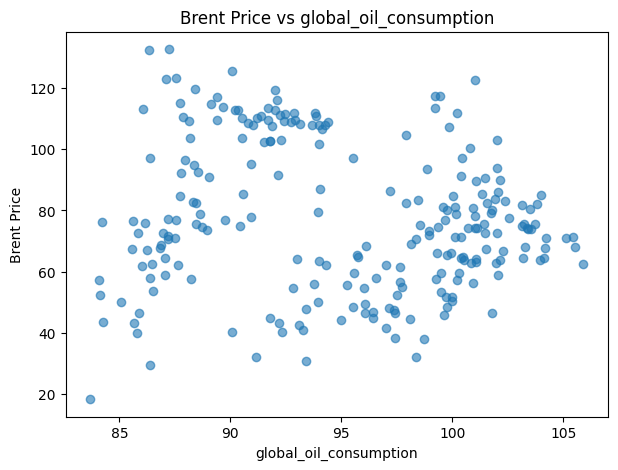

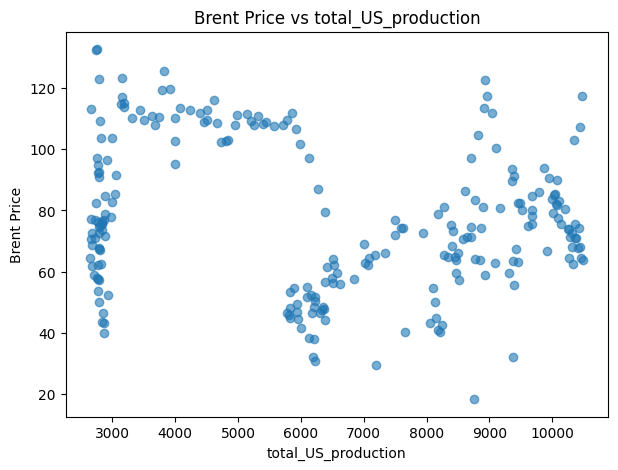

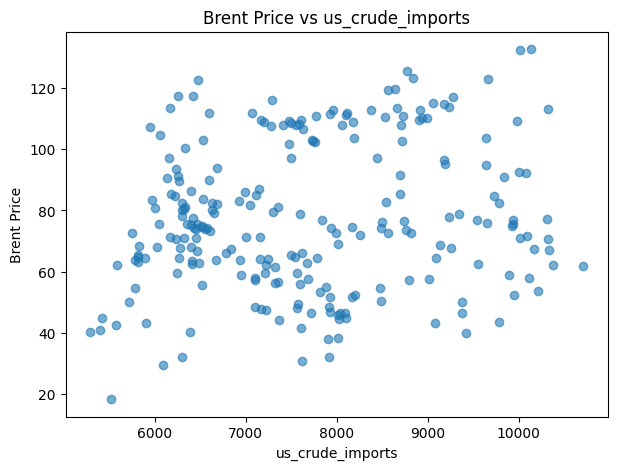

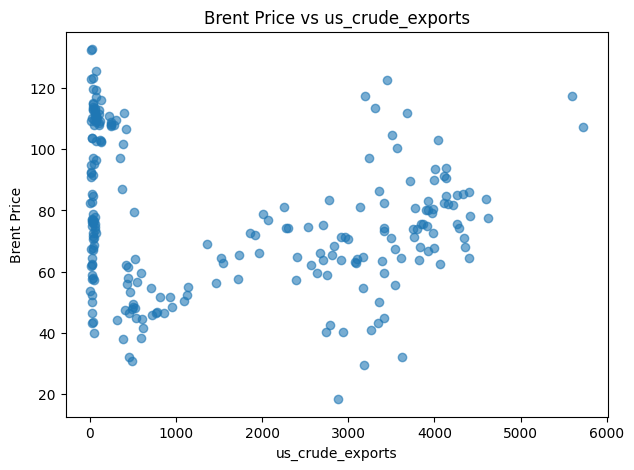

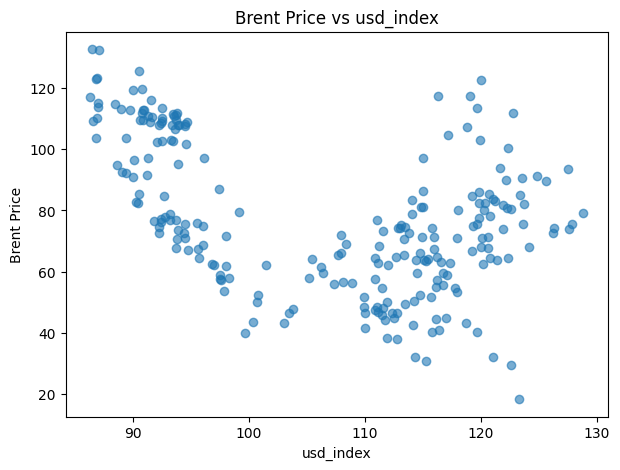

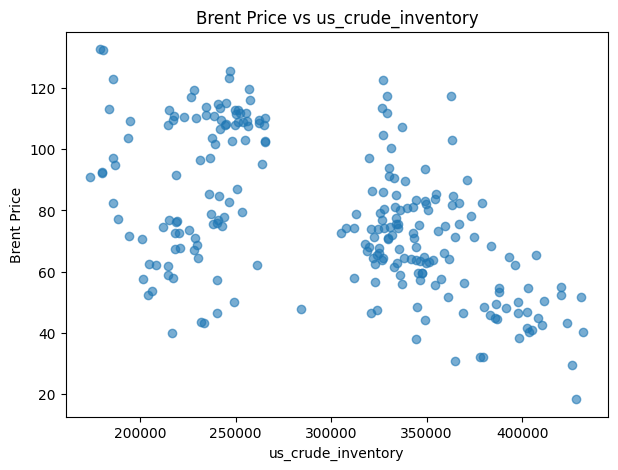

In [236]:
import matplotlib.pyplot as plt

for col in drivers:

    plt.figure(figsize=(7,5))

    plt.scatter(
        df[col],
        df['brent_price'],
        alpha=0.6
    )

    plt.xlabel(col)
    plt.ylabel('Brent Price')
    plt.title(f'Brent Price vs {col}')

    plt.show()

In [241]:
features = [
    'brent_price',
    'wti_price',
    'opec_crude_production',
    'total_non_opec_production_mbpd',
    'global_oil_consumption',
    'total_US_production',
    'us_crude_imports',
    'us_crude_exports',
    'usd_index',
    'us_crude_inventory'
]

correlation_matrix = (
    df[features]
    .corr()
)

correlation_matrix

,brent_price,wti_price,opec_crude_production,total_non_opec_production_mbpd,global_oil_consumption,total_US_production,us_crude_imports,us_crude_exports,usd_index,us_crude_inventory
brent_price,1.000000,0.973778,-0.018070,-0.206357,-0.135560,-0.195668,0.172261,-0.141059,-0.469854,-0.533877
wti_price,0.973778,1.000000,-0.010030,-0.246606,-0.178439,-0.233184,0.223913,-0.155844,-0.480861,-0.583435
opec_crude_production,-0.018070,-0.010030,1.000000,-0.257901,-0.089490,-0.394937,0.519061,-0.535874,-0.311206,-0.285489
total_non_opec_production_mbpd,-0.206357,-0.246606,-0.257901,1.000000,0.904590,0.959287,-0.821603,0.866232,0.866731,0.705963
global_oil_consumption,-0.135560,-0.178439,-0.089490,0.904590,1.000000,0.888249,-0.726751,0.768154,0.808405,0.690816
total_US_production,-0.195668,-0.233184,-0.394937,0.959287,0.888249,1.000000,-0.898381,0.935994,0.910075,0.767982
us_crude_imports,0.172261,0.223913,0.519061,-0.821603,-0.726751,-0.898381,1.000000,-0.812729,-0.777704,-0.762387
us_crude_exports,-0.141059,-0.155844,-0.535874,0.866232,0.768154,0.935994,-0.812729,1.000000,0.875960,0.665239
usd_index,-0.469854,-0.480861,-0.311206,0.866731,0.808405,0.910075,-0.777704,0.875960,1.000000,0.844923
us_crude_inventory,-0.533877,-0.583435,-0.285489,0.705963,0.690816,0.767982,-0.762387,0.665239,0.844923,1.000000


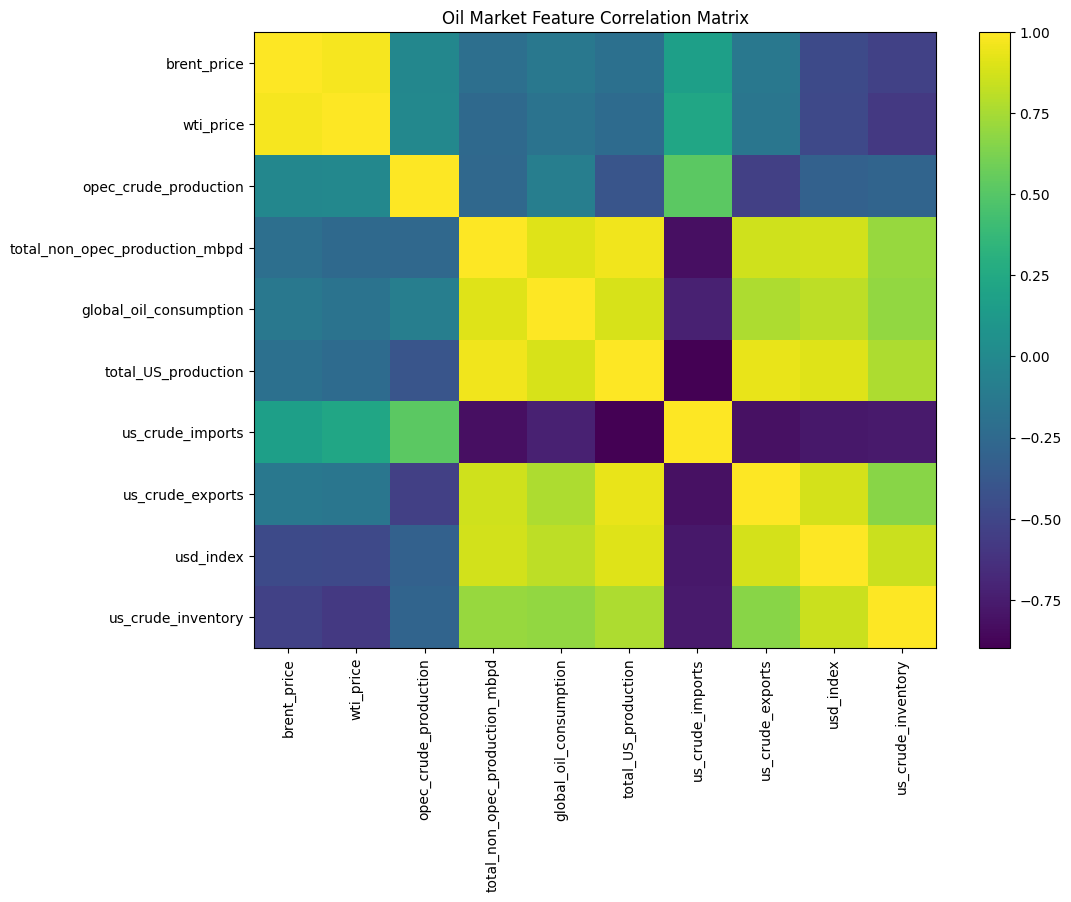

In [242]:
fig, ax = plt.subplots(figsize=(11,8))

im = ax.imshow(
    correlation_matrix,
    aspect='auto'
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))

ax.set_xticklabels(
    features,
    rotation=90
)

ax.set_yticklabels(features)

plt.colorbar(im)

plt.title(
    "Oil Market Feature Correlation Matrix"
)

plt.show()

##### Change MoM and YoY

In [243]:
cols = [
    'brent_price',
    'opec_crude_production',
    'total_non_opec_production_mbpd',
    'global_oil_consumption',
    'usd_index'
]

for col in cols:

    df[f'{col}_pct_change'] = (
        df[col]
        .pct_change() * 100
    )

In [244]:
for col in cols:

    df[f'{col}_yoy'] = (
        df[col].pct_change(12) * 100
    )

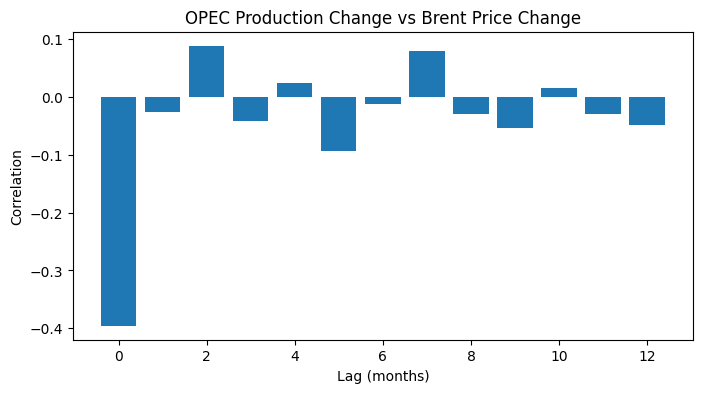

In [245]:
lag_corr = []

for lag in range(13):

    corr = (
        df['opec_crude_production_pct_change']
        .shift(lag)
        .corr(df['brent_price_pct_change'])
    )

    lag_corr.append(corr)


plt.figure(figsize=(8,4))

plt.bar(
    range(13),
    lag_corr
)

plt.xlabel("Lag (months)")
plt.ylabel("Correlation")
plt.title(
    "OPEC Production Change vs Brent Price Change"
)

plt.show()

In [255]:
features1 = [
    'brent_price',
    'wti_price',
    'opec_crude_production',
    'total_non_opec_production_mbpd',
    'global_oil_consumption',
    'total_US_production',
    'us_crude_imports',
    'us_crude_exports',
    'usd_index',
    'us_crude_inventory'
]

change_df = df[features1].pct_change()

change_corr = change_df.corr()

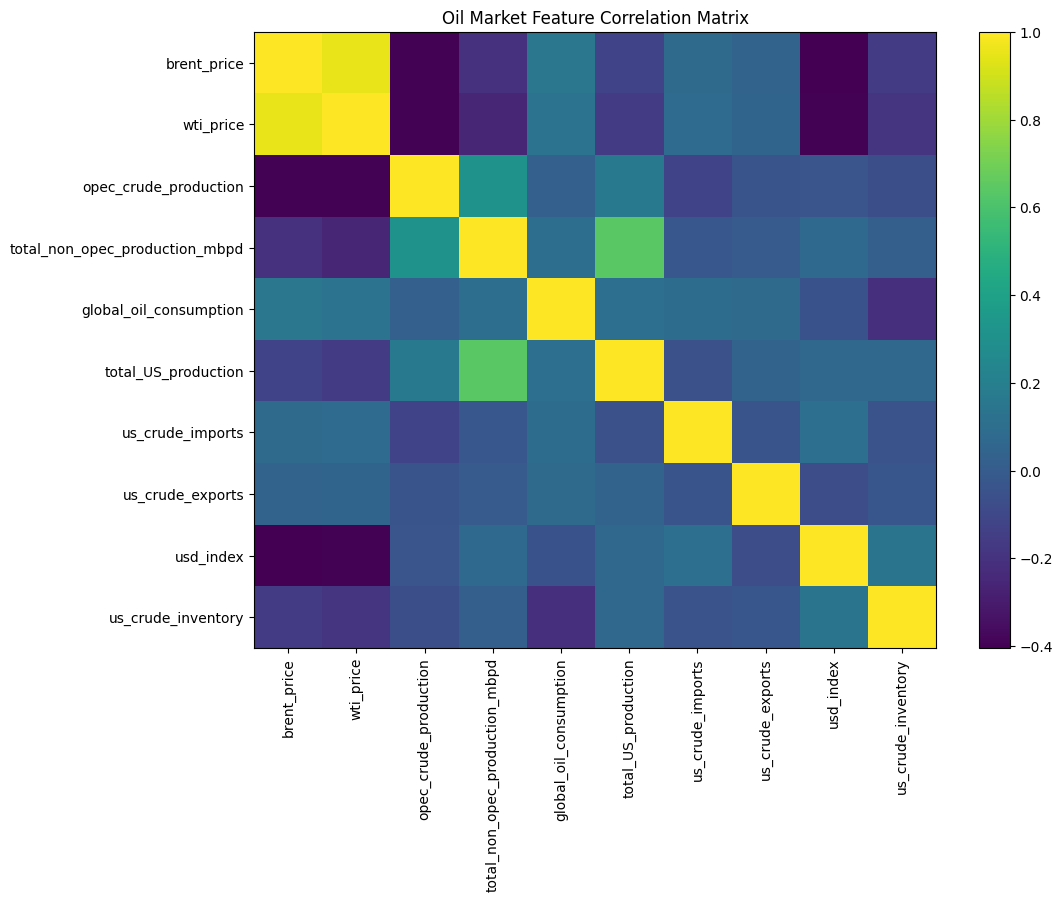

In [256]:
fig, ax = plt.subplots(figsize=(11,8))

im = ax.imshow(
    change_corr,
    aspect='auto'
)

ax.set_xticks(range(len(features1)))
ax.set_yticks(range(len(features1)))

ax.set_xticklabels(
    features,
    rotation=90
)

ax.set_yticklabels(features1)

plt.colorbar(im)


plt.title(
    "Oil Market Feature Correlation Matrix"
)

plt.show()

In [257]:
df.to_csv("functional_data.csv", index=False)